# 04 · Video inference and temporal segmentation

The dataset has no prayer *videos*, so this demo uses a **synthetic clip** assembled from dataset images in prayer
order (faces blurred). The deployed model was trained on these images: the clip demonstrates the mechanics
(decoding, sampling, temporal decoding, annotation) — **it is not an accuracy measurement**. The quantitative
evaluation of the temporal decoder is the semi-synthetic benchmark at the end.

In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "default.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("GLOG_minloglevel", "2")
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
from salat_vision.config import get_config
from salat_vision.viz import apply_style
apply_style()
cfg = get_config()
print("project root:", ROOT)

project root: /home/user/Shalat-Postures-Detection


In [2]:
demo = ROOT / "artifacts/demo/demo_sequence.mp4"
if not demo.exists():
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "scripts/make_demo_video.py")], check=True)
plan = json.loads((ROOT / "artifacts/demo/demo_sequence.json").read_text())
print(f"clip: {plan['duration']} s, {plan['size']}, {len(plan['timeline'])} planned phases")
pd.DataFrame(plan["timeline"])[["start", "end", "phase"]].T

clip: 42.92 s, [1280, 720], 13 planned phases


,0,1,2,3,4,5,6,7,8,9,10,11,12
start,0.0,5.0,8.0,10.48,13.48,15.96,18.96,22.96,25.96,28.44,31.44,33.92,36.92
end,5.0,8.0,10.48,13.48,15.96,18.96,22.96,25.96,28.44,31.44,33.92,36.92,42.92
phase,berdiri,rukuk,iktidal,sujud,duduk_antara_sujud,sujud,berdiri,rukuk,iktidal,sujud,duduk_antara_sujud,sujud,tasyahud


## Run the full pipeline (real model bundle)

In [3]:
from salat_vision.inference.predictor import PosturePredictor
from salat_vision.inference.video import analyze_video
out_video = ROOT / "artifacts/demo/demo_annotated_notebook.mp4"
with PosturePredictor(cfg=cfg) as pred:
    res = analyze_video(demo, pred, cfg, annotate_path=out_video)
print("decoder:", res["decoder"], "| frames analysed:", res["performance"]["frames_analyzed"],
      "| analysis fps:", res["performance"]["analysis_fps"], "| real-time factor:", res["performance"]["realtime_factor"])
pd.DataFrame(res["segments"])[["start", "end", "duration", "label", "confidence", "uncertain", "evidence"]]

decoder: hmm_local | frames analysed: 215 | analysis fps: 10.12 | real-time factor: 2.02


,start,end,duration,label,confidence,uncertain,evidence
0,0.0,5.00,5.00,Berdiri (Qiyam),0.7301,False,visual + context
1,5.0,8.20,3.20,Rukuk,0.6886,False,visual
2,8.2,10.60,2.40,Iktidal,0.8544,False,visual + context
3,10.6,13.60,3.00,Sujud,0.8505,False,visual
4,13.6,16.20,2.60,Duduk di Antara Dua Sujud,0.8486,False,visual + context
5,16.2,19.20,3.00,Sujud,0.9526,False,visual
6,19.2,23.20,4.00,Berdiri (Qiyam),0.8130,False,visual + context
7,23.2,26.20,3.00,Rukuk,0.7727,False,visual
8,26.2,28.60,2.40,Iktidal,0.4436,True,visual + context
9,28.6,31.60,3.00,Sujud,0.9600,False,visual


In [4]:
s = res["summary"]
print("observed sequence:", " -> ".join(s["sequence"]))
print("cycles observed:", s["cycles_observed"], "| uncertain segments:", s["n_uncertain_segments"], f"({s['uncertain_seconds']} s)")
pd.Series(s["phase_seconds"], name="seconds").to_frame().T

observed sequence: berdiri -> rukuk -> iktidal -> sujud -> duduk_antara_sujud -> sujud -> berdiri -> rukuk -> iktidal -> sujud -> duduk_antara_sujud -> sujud -> tasyahud
cycles observed: 2 | uncertain segments: 2 (8.12 s)


,berdiri,rukuk,iktidal,sujud,duduk_antara_sujud,tasyahud
seconds,9.0,6.2,4.8,12.0,5.2,5.72


## Raw frame predictions vs. temporal decoding vs. the clip plan

In [5]:
from salat_vision.viz import PHASE_COLORS, NEUTRAL, VISUAL_COLORS
fig, ax = plt.subplots(figsize=(12, 2.4))
rows = [("plan", [{**t, "uncertain": False} for t in plan["timeline"]]), ("raw", res["raw_segments"]), ("decoded", res["segments"])]
for r, (name, segs) in enumerate(rows):
    for seg in segs:
        ax.add_patch(plt.Rectangle((seg["start"], r - 0.32), seg["end"] - seg["start"] - 0.06, 0.64,
                                   color=NEUTRAL if seg.get("uncertain") else PHASE_COLORS[seg["phase"]]))
ax.set_xlim(0, res["video"]["duration_seconds"]); ax.set_ylim(2.6, -0.6); ax.set_yticks(range(3), [r[0] for r in rows])
ax.set_xlabel("time (s)"); plt.show()
print(f"raw segments: {len(res['raw_segments'])} -> decoded: {len(res['segments'])}")
truth = [next(t['phase'] for t in plan['timeline'] if t['start'] <= f['t'] < t['end']) for f in res['frames']]
print("frame agreement with the plan (seen images):", np.mean([a == f['phase'] for a, f in zip(truth, res['frames'])]).round(3))

raw segments: 24 -> decoded: 13
frame agreement with the plan (seen images): 0.967


In [6]:
fr = pd.DataFrame([{"t": f["t"], **(f["probabilities"] or {})} for f in res["frames"]])
fig, ax = plt.subplots(figsize=(12, 3))
for c in ["qiyam", "ruku", "sujud", "julus"]:
    ax.plot(fr.t, fr[c], color=VISUAL_COLORS[c], lw=1.6, label=c)
ax.axhline(cfg["inference"]["uncertainty_threshold"], color="#898781", lw=1)
ax.set_ylim(0, 1); ax.set_xlabel("time (s)"); ax.set_ylabel("frame score"); ax.legend(ncol=4, loc="upper right"); plt.show()

## Annotated frames

In [7]:
import imageio_ffmpeg
gen = imageio_ffmpeg.read_frames(str(out_video), output_params=["-vf", "fps=0.25"])
meta = next(gen); W, H = meta["size"]
frames = [np.frombuffer(b, np.uint8).reshape(H, W, 3) for b in gen]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, f in zip(axes, frames[1:5]):
    ax.imshow(f); ax.set_axis_off()
plt.show()

## Temporal decoder benchmark (semi-synthetic, real out-of-fold scores)

,regime,decoder,phase_acc,edit,f1_50,seg_ratio
0,segment,raw,0.704,23.774,25.632,4.316
1,segment,smoothing,0.755,68.323,66.376,1.102
2,segment,hmm,0.678,76.033,66.676,0.825
3,segment,hmm_local,0.792,75.685,71.011,0.825
4,iid,raw,0.715,14.761,14.742,6.571
5,iid,smoothing,0.867,80.864,80.583,1.171
6,iid,hmm,0.918,98.188,95.418,0.983
7,iid,hmm_local,0.942,98.188,96.276,0.983


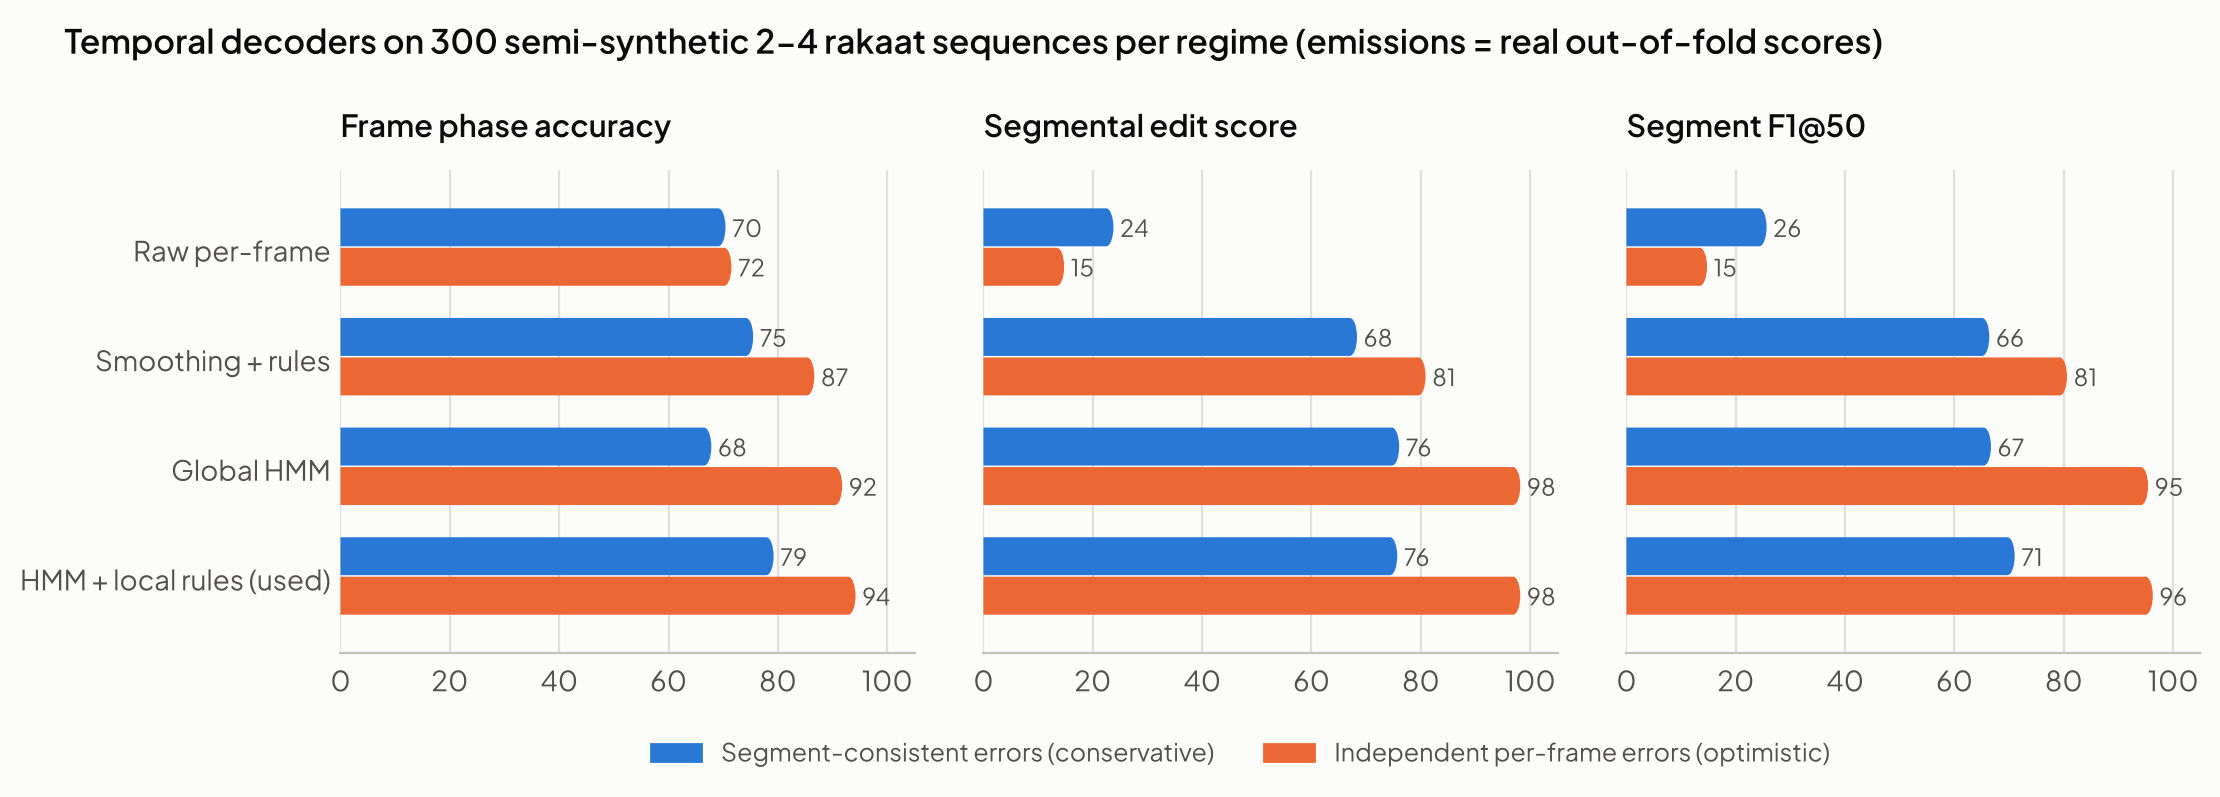

In [8]:
tb = json.loads((ROOT / "artifacts/metrics/temporal_benchmark.json").read_text())
rows = [{"regime": m, "decoder": d, **{k: tb["results"][m][d][k]["mean"] for k in ("phase_acc", "edit", "f1_50", "seg_ratio")}}
        for m in ("segment", "iid") for d in ("raw", "smoothing", "hmm", "hmm_local")]
display(pd.DataFrame(rows).round(3))
display(Image(str(ROOT / "artifacts/figures/temporal_benchmark.png"), width=980))

The global grammar HMM gives the cleanest segmentation, but when a whole segment is misrecognised it can desynchronise
the contextual names (iktidal vs. standing, tasyahud vs. sitting between prostrations). The deployed **hybrid** keeps
the HMM segmentation and names phases from local context — best on phase accuracy and F1@50 in both error regimes,
selected on a separate validation seed.

In [9]:
dst = ROOT / "artifacts/predictions/demo_analysis_notebook.json"
dst.parent.mkdir(parents=True, exist_ok=True)
dst.write_text(json.dumps({k: v for k, v in res.items() if k != "frames"}, indent=1))
print("saved", dst.relative_to(ROOT))

saved artifacts/predictions/demo_analysis_notebook.json
